정량 데이터 : 수치화된 데이터
<br>정성 데이터 : 수치화 되지 않은 데이터 - 그림 사진 문장(자연어로 구성된)

# 주장과 근거의 관계
개선안의 한 문장은 무엇이 문제다 주장이 있고 그 증거로 이런 숫자가 있다 근거로 구성되어 있다. 근거가 왜 주장을 뒷받침 하는지에 대한 설명이 있어야 하고 이 설명을 연결고리라고 일컫는다. (종이나 피그마 메모장 등에 가볍게 주장 근거 연결고리 등을 메모할 필요가 있다)

데이터: 부산항만공사 선박 입출항집계, 해양수산부 선박관제정보
- 주장: 통제 해제 직후 관제의 입항 순서 지정 업무가 몰린다.
- 연결고리: 뒷받침 근거 데이터 입항 한 건 -> 관제가 순서를 지정한 입항 건수
- 근거: 통제가 해제된 다음 날 가장 바쁜 한 시간 입항 척수는 13척이었고 평소에는 10척 정도였다.

같은 근거가 어떤 주장은 잘 뒷받침하고 어떤 주장은 전혀 뒷받침 하지 못할 수 있다.
- 근거: 통제 해제 직후 들어온 컨테이너선의 항해시간이 직전 기간보다 17.6시간 길다.

- 주장: 통제 기간 중에서는 바다에서 기다린 선박이 섞여 있다.
- 연결고리: 항해 시간에는 부산항 앞 대기가 섞여 있다.

- 주장: 입항 순서를 미리 정하면 선박 대기가 줄어든다.
- 연결고리: 순서를 미리 정하면 대기의 총량이 줄어든다.

# 근거 매트릭스
근거 매트릭스는 하나의 근거가 여러 주장을 뒷받침하기도 하고 어떤 주장은 근거가 없기도 한데 이러한 관계를 행열로 표현해 놓은 것을 의미한다. 주장이 행이 되고 근거가 열로 구성되어있다.




In [23]:
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False # 한글 폰트에서 깨짐 방지

In [31]:
from matplotlib.colors import ListedColormap
# 색지도
import pandas as pd

claims = ['A1','A2','A3','B1','B2','D1']
evidence_ids = ['Q1','Q2','Q3','Q4','Q5','Q6','Q7','S1','S2','S3'] #Q는 정량 근거, S는 정성 근거

links = [
    ('A1','Q1',1),('A1','Q2',1),('A1','S1',1),
    ('A2','Q3',1),
    ('A3','Q4',-1),('A3','Q5',-1),('A3','S2',1),
    ('B1','Q6',1),('B1','S3',1),
    ('B2','S3',1),
    ('D1','Q7',1)
]


matrix = pd.DataFrame(0,index=claims, columns=evidence_ids)

for claim, ev, sign in links:
    matrix.loc[claim, ev] = sign

print(matrix)
print(matrix.shape, (matrix !=0).sum().sum())

    Q1  Q2  Q3  Q4  Q5  Q6  Q7  S1  S2  S3
A1   1   1   0   0   0   0   0   1   0   0
A2   0   0   1   0   0   0   0   0   0   0
A3   0   0   0  -1  -1   0   0   0   1   0
B1   0   0   0   0   0   1   0   0   0   1
B2   0   0   0   0   0   0   0   0   0   1
D1   0   0   0   0   0   0   1   0   0   0
(6, 10) 11


In [32]:
cmap = ListedColormap(['#c8553d','white','#3d7cc8'])

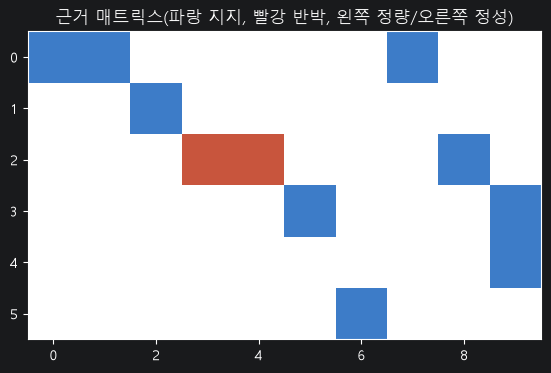

In [33]:
fig, ax = plt.subplots(figsize=(9,4))
ax.imshow(matrix.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_title('근거 매트릭스(파랑 지지, 빨강 반박, 왼쪽 정량/오른쪽 정성)')
plt.show()

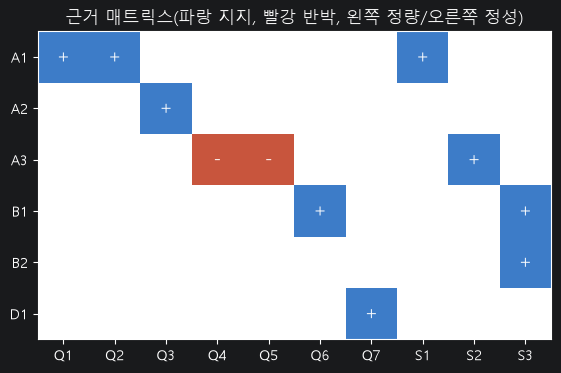

In [34]:
fig, ax = plt.subplots(figsize=(9,4))
ax.imshow(matrix.values, cmap=cmap, vmin=-1, vmax=1)

for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        value = matrix.iloc[i, j]
        if value:
            ax.text(j,i, "+" if value > 0 else "-", ha="center", va="center", color="white", fontsize=13)
# 왜 j i라 할까? x와 y는 뒤집혀있기 때문에
# 이미지 분석시 세로와 가로 위치가 바뀜

ax.set_xticks(range(len(evidence_ids)), evidence_ids)
ax.set_yticks(range(len(claims)), claims)
ax.set_title('근거 매트릭스(파랑 지지, 빨강 반박, 왼쪽 정량/오른쪽 정성)')
plt.show()



In [37]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False


def load_dataset(filename, cols=None):
    BASE_DIR = './data'
    EXTENSION = '.csv'
    TARGET_PATH = f'{BASE_DIR}/{filename}{EXTENSION}'
    try:
        return pd.read_csv(TARGET_PATH)
    except FileNotFoundError:
        return None
    except UnicodeDecodeError:
        return pd.read_csv(TARGET_PATH, encoding='euc-kr', usecols= cols if cols else None)

# 입출항 집계

In [42]:
d004 = load_dataset('입출항',['입항일시'])
d004['입항'] = pd.to_datetime(d004['입항일시'], format='%Y-%m-%d %H:%M', errors='coerce')
d004 = d004[d004['입항'].dt.year.between(2019,2024)]

print(len(d004))

272861


# 관제정보

In [45]:
d012 = load_dataset('선박관제정보', cols=['관제항구','입항일시','상태구분'])
d012 = d012[(d012['관제항구'] == '부산') & (d012['상태구분'] != '삭제')]

d012['입항'] = pd.to_datetime(d012['입항일시'], errors='coerce')
d012.head()
# d012.info()

,관제항구,입항일시,상태구분,입항
0,부산,2024-05-01 01:10:00,수정,2024-05-01 01:10:00
4,부산,2024-05-01 03:00:00,수정,2024-05-01 03:00:00
6,부산,2024-05-01 09:00:00,수정,2024-05-01 09:00:00
8,부산,2024-05-01 07:35:00,수정,2024-05-01 07:35:00
13,부산,2024-05-01 08:35:00,수정,2024-05-01 08:35:00


In [49]:
d012.info()

<class 'pandas.DataFrame'>
Index: 41936 entries, 0 to 176737
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   관제항구    41936 non-null  str           
 1   입항일시    41936 non-null  str           
 2   상태구분    41936 non-null  str           
 3   입항      41936 non-null  datetime64[us]
dtypes: datetime64[us](1), str(3)
memory usage: 1.6 MB


In [48]:
print(len(d012), d012['입항'].min().date(), d012['입항'].max().date())

41936 2024-05-01 2025-07-31


In [53]:
# 기대선 대비 비율
# 그날 입항/ 직전달 28일 중앙값

daily_004 = d004['입항'].dt.normalize().value_counts().sort_index().asfreq('D', fill_value=0)
daily_012 = d012['입항'].dt.normalize().value_counts().sort_index().asfreq('D', fill_value=0)

In [54]:
overlap = pd.date_range('2024-05-01', '2024-12-31')
overlap

DatetimeIndex(['2024-05-01', '2024-05-02', '2024-05-03', '2024-05-04',
               '2024-05-05', '2024-05-06', '2024-05-07', '2024-05-08',
               '2024-05-09', '2024-05-10',
               ...
               '2024-12-22', '2024-12-23', '2024-12-24', '2024-12-25',
               '2024-12-26', '2024-12-27', '2024-12-28', '2024-12-29',
               '2024-12-30', '2024-12-31'],
              dtype='datetime64[us]', length=245, freq='D')

In [63]:
both = pd.DataFrame({
    'D004': daily_004.reindex(overlap),
    'D012': daily_012.reindex(overlap, fill_value=0),
})

In [60]:
# 기대선 대비 비율
# 그날 입항/ 직전달 28일 중앙값
ratio_004 = daily_004/daily_004.shift(1).rolling(28).median()
ratio_012 = daily_012/daily_012.shift(1).rolling(28).median()

# ratio_004['2024-10-20']
round(ratio_012['2024-10-20'],2)

np.float64(0.31)

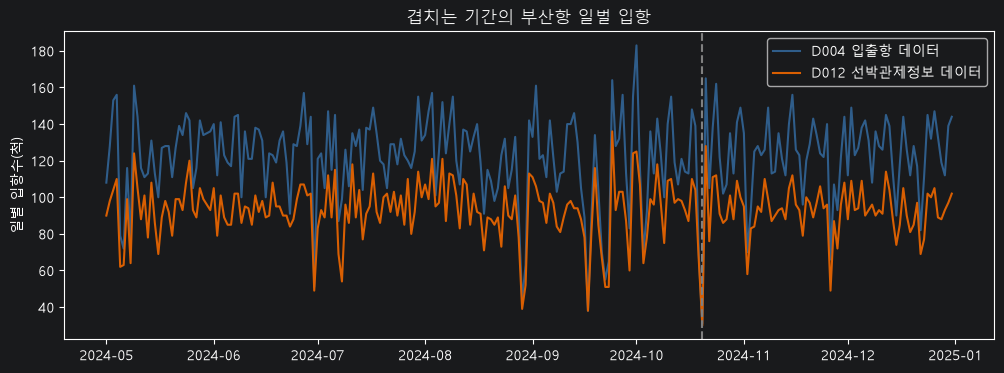

In [64]:
fig, ax = plt.subplots(figsize=(12,4))

ax.plot(both.index, both['D004'], color='#2f5d8a', label='D004 입출항 데이터')
ax.plot(both.index, both['D012'], color='#d95f02', label='D012 선박관제정보 데이터')

ax.axvline(pd.Timestamp('2024-10-20'), color='gray', linestyle='--')
ax.set_ylabel('일별 입항수(척)')
ax.set_title('겹치는 기간의 부산항 일벌 입항')

ax.legend()



plt.show()

In [65]:
level_ratio = (both['D012'] / both['D004']).median()
round(level_ratio, 2)

np.float64(0.76)

In [72]:
corr_level = both['D004'].corr(both['D012'])

In [79]:
corr_diff = both['D004'].diff().corr(both['D012'].diff()) # 재가 떨어지면 얘도 떨어짐

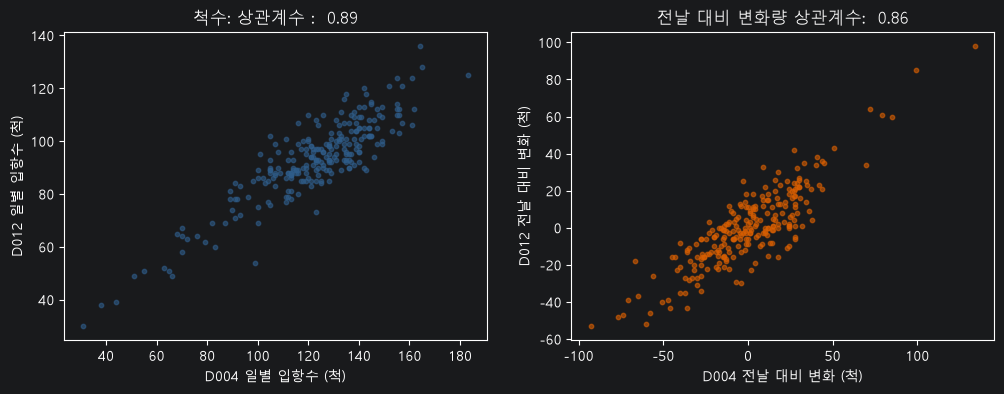

In [80]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(both['D004'], both['D012'], s=10, alpha=0.6, color='#2f5d8a')
axes[0].set_xlabel('D004 일별 입항수 (척)')
axes[0].set_ylabel('D012 일별 입항수 (척)')

axes[0].set_title(f'척수: 상관계수 : {corr_level : .2f}')

axes[1].scatter(both['D004'].diff(), both['D012'].diff(), s=10, alpha=0.6, color='#d95f02')
axes[1].set_xlabel('D004 전날 대비 변화 (척)')
axes[1].set_ylabel('D012 전날 대비 변화 (척)')
axes[1].set_title(f'전날 대비 변화량 상관계수: {corr_diff : .2f}')
plt.show()

In [77]:
change = both.diff().dropna()
mismatch = np.sign(change['D004']) != np.sign(change['D012']) # 미스매치
print(round(mismatch.mean() * 100, 1)) # 같이 변하지 않는 것의 비율

big_change = change['D004'].abs()> 30 #전날 대비 30척 이상인 날의 비율
print(big_change.sum())

22.5
52


# 근거evidence
근거는 주장이 옳다고 믿을 이유를 제공하는 사실이다. 개선안에서는 근거가 중요하다. 개선안을 읽는 사람이 대개 해당 업무를 직접적으로 분석하지 않은 사람이기 때문이다. (의사결정자의 의사 결정에 영향을 미치기 때문에 무조건 객관적인 사실만을 보여야 한다)

'분석가가 알고 있는 사실, 알고 있다' 문서 안에서 다른 사람이 확인할 수 있는 형태 및 근거를 제시할 수 있어야 한다.

## 주장, 근거, 연결고리
내일 오후에 비가 온다. <주장> 서쪽에서 저기압이 다가오고 있다. <근거>
<br>저기압이 다가오면 대개 비가 온다 라는 일반 원리가 하나 숨어 있다.
<br>근거가 왜 주장을 뒷받침 하는지 설명하는 숨은 전제를 연결고리라고 일컫는다.

```text
- 주장: 월요일 오전 신고 처리 담당자의 업무가 주말 입항분으로 밀린다.

- 근거: 허가의 34.3%가 월요일에 기록됨. 월요일 허가의 65.5%가 금~일요일 입항에서 비롯됨.

- 연결고리: 허가일자는 담당자가 신고를 처리한 시각이다.
```

- 주장: 선박이 주말에 기다린다.
- 근거: 허가의 34.3%가 월요일에 처리된다.
- 연결고리: '허가가 있어야만 선박이 움직일 수 있다'라는 것이 성립해야 된다.
    - 허가가 출항 예정보다도 늦게 기록된 입항이 88%가 넘는다. <연결고리가 성립이 안되므로 이 주장은 성립이 안된다>

## 근거 카드
근거를 수치 하나만 적어두면 나중에 다시 찾거나 검증하기 어려울 수 있다.
- 내용: 수치나 인용문 자체
- 단위/정의: 무엇을 어떻게 측정했는가
- 기준 기간: 언제의 값인가
- 비교 기준: 무엇과 비교하여 크기가 작은가
- 출처: 어느 데이터/누구의 말인가
- 가공 방법:어떤 행을 빼고 어떻게 계산했는가

`허가의 34.3%가 월요일에 처리된다.` 평소 수준 주말 제외하고 주일(월~금) 공평하게 나눠서 분배하면 20%, 14.3%

## 정량 근거quantitative evidence
정량 근거는 측정한 값으로 두성 되어있는 근거를 의미한다. 정량 근거가 설명할 수 있는(뒷잗침 하는) 내용은 크기와 범위이다.

- 월요일 일이 몰려요
- 허가 5만 3천 여견 가운데 34.3%인 약 1만 8천 정도가 월요일에 처리돼요.

KPI는 상태를 요약한 값이고 근거는  특정 주장을 뒷받침하는 값이다.
같은 KPI라도 어떤 주장 옆에 놓이느냐에 따라서 강한거가 될 수도 있고 아무런 관계없는 그냥 지표로 델 수도 있다.

## KPI룰 근거로 변환
온도계가38.5도를 나타내고 있다.
체온일 경우, 정상 체온이 36.5도 안팎이기 때문에 현재 온도계가 나타내고 있는 값이 높은 편이고 열이 있다가 성립될 수 있다.
3일 동안 온도계가 38.x도를 가리키고 있다.

KPI를 근거로 바꾸려면 `값 -> 비교 -> 해석`의 과정이 있어야 한다.
- 값: 지표를 계산
- 비교: 기준선, 다른 집단, 다른 기간이라 비교
- 해석: 비교 결과가 어떤 주장을 뒷받칩 하는지 연결고리를 찾는다.

- 값: '24 컨테이너선 동시 체류 척수 평균 37.4척
- 비교: 95번째 백분위수 46척, 최대 62척('24-02-17, 설 연휴 직후)
- 해석: 명절 직후 수일간 컨테이너 부두 혼잡이 평소의 1.3~1.7배 정도 커진다.

비교기분 같은 경우에는 주장에 맞게 선택해야 한다.
기준선 비교는 같은 대상의 과거값이나 평균값과 비교하는 것이기 때문에 평소보다 나빠졌다라는 주장에도 어울린다. 집단비교를 하면 외항, 내항, 주말 입항, 평일 입항처럼 다른 집단이랑 비교하는 것이기 때문에 특정 집단에서 문제가 크다라는 주장에 어울린다. 목표 비교는 정해둔 목표값과 현재값을 비교하는 것이기 때문에 목표가 미치지 못한다라는 주장에 어울린다.

### 분모 선택 *
비율로 되어있는 근거는 분모에 따라서 전혀 다른 이야기를 할 수 있다.

- 연결되지 않은 입항 15000건 가운데 내항이 14990이다. <미연결 입항건 중에서>
- 내항 입항의 관제 연결률이 40.6%이다. <내향입항건>


